# TP4 - Procesamiento de arreglos

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

os.makedirs("audios", exist_ok=True)

# Pregunta 1

## Elección del subarreglo

En esta sección elegimos el subarreglo que vamos a utilizar. Primero, tenemos que determinar la distancia máxima entre sensores para evitar **aliasing espacial** a $F_c = 2000\text{ Hz}$. Con $c = 343\text{ m/s}$, la longitud de onda es $\lambda = c/F_c = 343/2000 = 17{,}15\text{ cm}$, así que necesitamos $d < \lambda/2 = 8{,}58\text{ cm}$.

Entonces podemos descartar el arreglo de $16\text{ cm}$ entre sensores, debido a que supera $\lambda/2$ y, por lo tanto, va a presentar aliasing espacial.

Entre los dos restantes ($4\text{ cm}$ y $8\text{ cm}$), ambos tienen **9 sensores**. Esto hace que el de $8\text{ cm}$ duplique la apertura ($64\text{ cm}$ frente a $32\text{ cm}$), duplicando la resolución espacial y capturando más señal/energía en función de la apertura y la geometría del arreglo. Además, una vez que se cumple la condición para evitar el aliasing espacial, reducir aún más la distancia entre sensores (con la misma cantidad de elementos) achica la apertura y aporta información más correlacionada/redundante entre canales cercanos.

Por estas razones, elegimos el arreglo con $8\text{ cm}$ entre sensores (abajo hay una tabla que resume todos los valores).

*Nota sobre $F_c = 2000\text{ Hz}$:* aunque la voz y la radio contienen energía tanto por debajo como por encima de $2000\text{ Hz}$, $F_c$ no es una portadora física de modulación sino una **frecuencia central de análisis**. Como el desfasaje entre sensores $\Delta\phi = 2\pi f \frac{d\sin\theta}{c}$ depende simultáneamente de $f$ y $\theta$, hace falta asumir banda angosta para que el desfasaje se deba únicamente a $\theta$, la variable física que nos interesa. Más específicamente, la banda debería estar centrada en $2000\text{ Hz}$, dentro de la banda vocal y cumpliendo $d < \lambda/2$ (muy cerca del límite $\lambda/2 \approx d$).

| Criterio | 4 cm | 8 cm | 16 cm |
|---|---|---|---|
| Aliasing espacial ($d < \lambda/2$) | No | No (justo) | **Sí** |
| Apertura | 32 cm | 64 cm | 96 cm |
| Resolución angular | Peor | Buena | Mejor, pero ambigua |
| Sensores | 9 | 9 | 7 |

In [2]:
# Parámetros físicos y geometría del arreglo
ARCHIVO = "mtms-arrC1A.wav"
Fc = 2000.0          # frecuencia central de análisis [Hz]
c = 343.0            # velocidad del sonido [m/s]
lam = c / Fc         # longitud de onda [m]
T_BLOQUE = 0.1       # duración de cada bloque temporal [s]
NFFT_ESP = 512       # puntos de la FFT espacial (zero-padding)

# Posiciones de los 15 micrófonos [m], tomando el elemento 0 como origen
pos = np.array([0.00, 0.16, 0.24, 0.32, 0.36, 0.40, 0.44, 0.48, 0.52,
                0.56, 0.60, 0.64, 0.72, 0.80, 0.96])

subarreglos = {
    "4 cm":  [3, 4, 5, 6, 7, 8, 9, 10, 11],
    "8 cm":  [1, 2, 3, 5, 7, 9, 11, 12, 13],
    "16 cm": [0, 1, 3, 7, 11, 13, 14],
}

ELEGIDO = "8 cm"
SUB = subarreglos[ELEGIDO]
d = float(np.mean(np.diff(pos[SUB])))

# Carga única del audio: la grabación cruda posee offset DC por canal (+51 a +325)
# y fuerte energía por debajo de 100 Hz (zumbido de 60 Hz y deriva), por lo que removemos la media
Fs, x_raw = wavfile.read(ARCHIVO)
x = x_raw.astype(float).T
x -= np.mean(x, axis=1, keepdims=True)

xs = np.take(x, SUB, axis=0)
K, N = xs.shape
n = np.arange(N)
print(f"Fs = {Fs} Hz, canales totales = {x.shape[0]}, duración = {N/Fs:.1f} s, dtype original = {x_raw.dtype}")
print(f"Sub-arreglo {ELEGIDO}: K = {K} sensores, d = {d*100:.1f} cm, lambda/2 = {lam/2*100:.2f} cm")

Fs = 16000 Hz, canales totales = 15, duración = 34.0 s, dtype original = int16
Sub-arreglo 8 cm: K = 9 sensores, d = 8.0 cm, lambda/2 = 8.58 cm


## Elección del ancho de banda $B$

A la hora de escoger el ancho de banda tenemos un compromiso.

**Si $B$ es demasiado chico:** capturamos poca energía, debido a que estamos considerando menos frecuencias. Además, cuando bajamos la frecuencia de muestreo a $F_{s2} \approx B$ (esto se hace para no guardar muestras redundantes y ahorrar cómputo), quedan muy pocos *snapshots* por bloque de $0{,}1\text{ s}$, lo que aumenta la varianza del espectro espacial (y complica estimar matrices de covarianza estables en la Pregunta 2).

**Si $B$ es demasiado grande:** se rompe la **hipótesis de banda angosta**. Para una apertura $L_{\text{ap}} = 0{,}64\text{ m}$, el retardo máximo de propagación entre extremos es $\tau_{\max} = L_{\text{ap}}/c \approx 1{,}87\text{ ms}$. Superar este límite hace que distintas frecuencias dentro de la banda sufran desfasajes incompatibles con una única frecuencia central $F_c$, deformando las fuentes alejadas de $0^\circ$ (*broadside*). Entonces, el desfasaje ya no puede explicarse únicamente por la diferencia de distancia que tiene que recorrer la señal hasta cada sensor, causando que la estimación de la dirección y de la señal empeoren notablemente.

Entonces, la idea es comparar varios valores de $B$, barriendo una grilla logarítmica de valores entre $25\text{ Hz}$ y $600\text{ Hz}$ para decidir con base en los datos.

Primero que nada, establecemos los parámetros que vamos a utilizar.

Otra cosa importante es que, para demodular la señal, elegimos un filtro pasabajos **Butterworth**. Es una buena opción porque tiene una respuesta bastante plana en la banda de paso y funciona bien en este caso. Además, lo aplicamos con `sosfiltfilt`, una función de Python que garantiza **fase cero** (sin distorsión de fase) y que todos los canales se vean afectados de la misma manera. Esto es especialmente importante en el **procesamiento espacial**, ya que queremos que el desfasaje entre sensores se deba únicamente al **ángulo de arribo**.

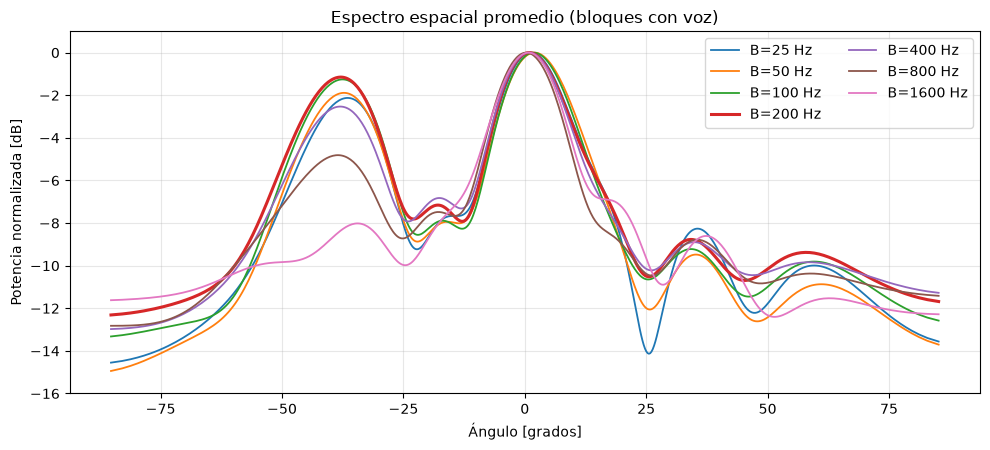

  B [Hz]  snapsh/bloque  ang pico  ancho -3dB  pico/piso dB
      25              2       1.2        14.9           8.1
      49              5       1.9        15.7           8.1
      78              8       1.9        14.9           8.4
      98             10       1.9        15.2           8.2
     200             20       1.0        14.9           7.5
     340             34       1.0        14.9           7.5
     536             55       0.5        14.4           7.6
     600             62       0.5        14.4           7.8


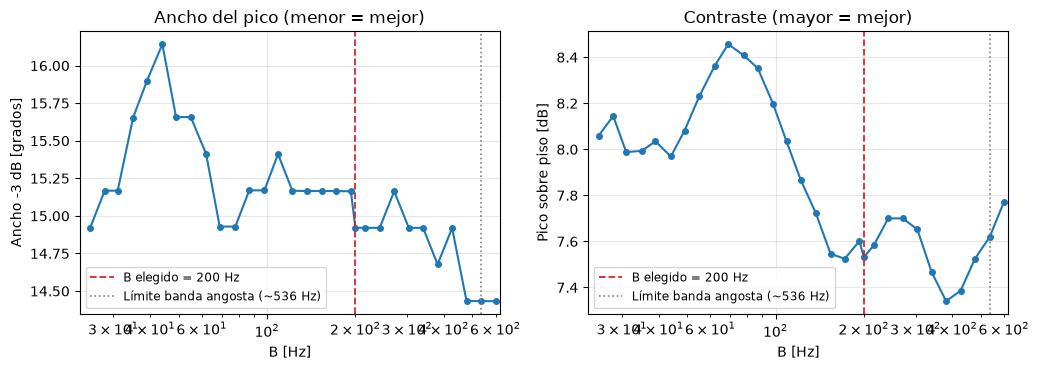

In [5]:
B_LISTA = np.unique(np.append(np.round(np.geomspace(25, 600, 29)).astype(int), [200]))
B_CURVAS = [25, 50, 100, 200, 400, 800, 1600]
B_ELEGIDO = 200.0
B_LIM_NB = c / (d * (K - 1))   # ~536 Hz (límite de banda angosta 1/tau_max)
PERCENTIL_VOZ = 75             # bloques de mayor potencia para evaluar la respuesta direccional

def demodular(B_val):
    xd_tmp = xs * np.exp(-2j * np.pi * Fc / Fs * n)
    sos = signal.butter(6, (B_val / 2) / (Fs / 2), btype="low", output="sos")
    xd_tmp = signal.sosfiltfilt(sos, xd_tmp, axis=1)
    M_dec = max(int(Fs // B_val), 1)
    return xd_tmp[:, ::M_dec], Fs / M_dec

def espectro_por_bloque(xd_in, Fs2_in, ventana=None):
    w = np.ones(xd_in.shape[0]) if ventana is None else np.asarray(ventana, dtype=float)
    w = w / np.sum(w)
    xw = xd_in * w[:, None]

    L_blk = max(int(round(T_BLOQUE * Fs2_in)), 1)
    nb_blk = xw.shape[1] // L_blk
    P_out = np.zeros((NFFT_ESP, nb_blk))
    for b in range(nb_blk):
        X = np.fft.ifft(xw[:, b * L_blk:(b + 1) * L_blk], n=NFFT_ESP, axis=0)
        P_out[:, b] = np.mean(np.abs(X) ** 2, axis=1)
    return np.fft.fftshift(P_out, axes=0), L_blk

def ancho_3dB(p_dB, k_pk, ang_eje):
    umbral = p_dB[k_pk] - 3
    i, j = k_pk, k_pk
    while i > 0 and p_dB[i - 1] >= umbral:
        i -= 1
    while j < len(p_dB) - 1 and p_dB[j + 1] >= umbral:
        j += 1
    return ang_eje[j] - ang_eje[i]

# Eje angular visible (|sin(theta)| <= 1)
psi = np.fft.fftshift(np.fft.fftfreq(NFFT_ESP)) * 2 * np.pi
u = psi * lam / (2 * np.pi * d)
visible = np.abs(u) <= 1
theta = np.degrees(np.arcsin(u[visible]))

def evaluar_B(B_val):
    xd_tmp, Fs2_tmp = demodular(float(B_val))
    P_tmp, L_tmp = espectro_por_bloque(xd_tmp, Fs2_tmp)
    P_tmp = P_tmp[visible, :]
    pot_bloque = P_tmp.sum(axis=0)
    activos = pot_bloque >= np.percentile(pot_bloque, PERCENTIL_VOZ)
    Pm = P_tmp[:, activos].mean(axis=1)
    Pm_dB = 10 * np.log10(Pm + 1e-12)
    k_pk = np.argmax(Pm_dB)
    return L_tmp, theta[k_pk], ancho_3dB(Pm_dB, k_pk, theta), Pm_dB[k_pk] - np.median(Pm_dB), Pm_dB - Pm_dB[k_pk]

resultados = []
for B_val in B_LISTA:
    L_tmp, ang_pk, w3, ctr, _ = evaluar_B(B_val)
    resultados.append((int(B_val), L_tmp, ang_pk, w3, ctr))

# Gráfico clásico de múltiples líneas para Espectro espacial promedio (25 a 1600 Hz)
plt.figure(figsize=(10, 4.6))
for B_c in B_CURVAS:
    _, _, _, _, curva = evaluar_B(B_c)
    lw = 2.2 if B_c == int(B_ELEGIDO) else 1.3
    plt.plot(theta, curva, linewidth=lw, label=f"B={B_c} Hz")
plt.xlabel("Ángulo [grados]")
plt.ylabel("Potencia normalizada [dB]")
plt.title("Espectro espacial promedio (bloques con voz)")
plt.ylim(-16, 1)
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tabla resumen en puntos representativos
print(f"{'B [Hz]':>8} {'snapsh/bloque':>14} {'ang pico':>9} {'ancho -3dB':>11} {'pico/piso dB':>13}")
for target in [25, 50, 75, 100, 200, 350, 536, 600]:
    row = min(resultados, key=lambda r: abs(r[0] - target))
    print(f"{row[0]:8d} {row[1]:14d} {row[2]:9.1f} {row[3]:11.1f} {row[4]:13.1f}")

# Gráficos de Ancho del pico y Contraste hasta 600 Hz con 30 puntos y marcas de B elegido / límite NB
Bs = [r[0] for r in resultados]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax[0].semilogx(Bs, [r[3] for r in resultados], "o-", markersize=4)
ax[0].axvline(B_ELEGIDO, color="tab:red", linestyle="--", linewidth=1.3, label=f"B elegido = {B_ELEGIDO:.0f} Hz")
ax[0].axvline(B_LIM_NB, color="gray", linestyle=":", linewidth=1.2, label=f"Límite banda angosta (~{B_LIM_NB:.0f} Hz)")
ax[0].set_xlim(23, 620)
ax[0].set_xlabel("B [Hz]"); ax[0].set_ylabel("Ancho -3 dB [grados]")
ax[0].set_title("Ancho del pico (menor = mejor)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8.5)

ax[1].semilogx(Bs, [r[4] for r in resultados], "o-", markersize=4)
ax[1].axvline(B_ELEGIDO, color="tab:red", linestyle="--", linewidth=1.3, label=f"B elegido = {B_ELEGIDO:.0f} Hz")
ax[1].axvline(B_LIM_NB, color="gray", linestyle=":", linewidth=1.2, label=f"Límite banda angosta (~{B_LIM_NB:.0f} Hz)")
ax[1].set_xlim(23, 620)
ax[1].set_xlabel("B [Hz]"); ax[1].set_ylabel("Pico sobre piso [dB]")
ax[1].set_title("Contraste (mayor = mejor)"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

### Configuración y elección del ancho de banda $B$

Como se explicó anteriormente, $B$ controla un compromiso: con un $B$ grande no cumplís la hipótesis de banda angosta (el retardo entre sensores deja de equivaler a un desfasaje a $F_c$), y un $B$ chico deja pocos *snapshots*.

Para decidir barremos $B$ entre $25$ y $600\text{ Hz}$ (30 valores en escala logarítmica) y, para cada uno, calculamos el espectro espacial promedio sobre los bloques de mayor potencia (percentil 75), donde habla el locutor.

**Snapshots por bloque.** Tras demodular y diezmar a $F_{s2}\approx B$, cada bloque de $T_{bloque}=0{,}1\text{ s}$ contiene $L\approx B\,T_{bloque}$ *snapshots*. Esencialmente, como tenés más información sobre la frecuencia, podés tener más *snapshots* sin tener información redundante. Más *snapshots* por bloque reducen la varianza del espectro espacial. Esto está representado con los valores del código, también presentes en la tabla justo debajo, donde tenés más *snapshots* al aumentar $B$.

| $B$ [Hz] | *Snapshots* / bloque | Ángulo pico [$^\circ$] | Ancho $-3\text{ dB}$ [$^\circ$] | Pico / piso [dB] |
|---|---|---|---|---|
| 25 | 2 | 1,2 | 14,9 | 8,1 |
| 49 | 5 | 1,9 | 15,7 | 8,1 |
| 78 | 8 | 1,9 | 14,9 | 8,4 |
| 98 | 10 | 1,9 | 15,2 | 8,2 |
| 200 | 20 | 1,0 | 14,9 | 7,5 |
| 340 | 34 | 1,0 | 14,9 | 7,5 |
| 536 | 55 | 0,5 | 14,4 | 7,6 |
| 600 | 62 | 0,5 | 14,4 | 7,8 |

**Pico principal ($\approx 0^\circ$).** Otra cosa que hace el código es medir tres cantidades sobre el pico principal del espectro espacial promedio (el máximo, cerca de $0^\circ$): su **ancho angular a $-3\text{ dB}$**, su contraste (nivel del pico menos la mediana del espectro) y su ángulo (la posición del máximo). Todos los valores generados también están en la tabla superior. Con estos valores se pueden hacer varias observaciones:

- El ancho es casi constante: varía entre $14{,}4^\circ$ y $16{,}1^\circ$ (unos $1{,}7^\circ$, alrededor del $10\%$), con valores irregulares para $B \lesssim 100\text{ Hz}$ y estables, en torno a $15^\circ$, para $B \gtrsim 100\text{ Hz}$. La leve disminución a $B$ grande ($\approx 0{,}5^\circ$, unos dos pasos de la grilla angular de $\approx 0{,}24^\circ$) no se interpreta como mejor resolución: un pico en *broadside* tiene $\tau\approx 0$ y no depende de $B$. La atribuimos a la varianza de la estimación. Con $L = 40$ fijo para todo $B$ el ancho varía entre $14{,}4^\circ$ y $16{,}4^\circ$.
- El ángulo del pico se mantiene entre $0{,}5^\circ$ y $1{,}9^\circ$ para todos los $B$ del barrido: el pico principal se corre levemente hacia $0^\circ$ al aumentar $B$ (de $1{,}9^\circ$ a $0{,}5^\circ$), como se puede ver en la figura del espectro espacial promediado y también en la tabla con todos los valores. No obstante, el corrimiento es de solo $1{,}4^\circ$, chico frente a un ancho de $\approx 15^\circ$.
- El contraste varía entre $7{,}3$ y $8{,}5\text{ dB}$ sin tendencia monótona, y depende de la mediana, que a su vez depende de las demás fuentes.

**Qué aportan (y qué no) estas métricas.** El barrido muestra dos cosas. Por un lado, para $B \lesssim 100\text{ Hz}$ (menos de unos $10$ *snapshots* por bloque) el ancho del pico es irregular, lo que sugiere una cota inferior razonable alrededor de $100\text{ Hz}$. Por otro lado, ni el ancho, ni el contraste ni el ángulo se degradan al aumentar $B$ hasta $600\text{ Hz}$. Esto no significa que cualquier $B$ sirva, sino que un pico en *broadside* no es sensible a la violación de la hipótesis de banda angosta, porque allí el retardo entre sensores es casi nulo para todas las frecuencias de la banda. Por eso estas métricas no sirven para fijar el límite superior de $B$.

Debido a que esta primera parte del código solo sugirió una cota inferior (no fijó el valor máximo de $B$), generamos un nuevo código que usa una fuente donde el retardo entre sensores sí es grande: la radio AM, cuyo lóbulo está fuera de eje ($\approx -37^\circ$, retardo entre extremos $\approx 1{,}13\text{ ms}$).

La idea es la siguiente: una componente a $F_c+\delta$ llega con fase $2\pi(F_c+\delta)\tau$, pero el *beamformer* (y la FFT espacial) compensan solo $2\pi F_c\tau$. El error de fase, $2\pi\delta\tau$, deja de ser despreciable cuando $B\,\tau_{ext}$ se acerca a $1$.

Este código (que está presente en la celda inferior) hace tres cosas:

- Calcula la pérdida de potencia teórica por pérdida de coherencia para una fuente en esa dirección, en función de $B$.
- Compara la tendencia con la caída del lóbulo fuera de eje observada en el espectro espacial promedio (solo de forma cualitativa: la caída observada es mayor que la teórica).
- Busca el $B$ a partir del cual la pérdida teórica supera $1\text{ dB}$, criterio que elegimos como umbral de degradación aceptable.

Ancho -3 dB : máx 16.14° (B=44 Hz) | mín 14.43° (B=600 Hz) | rango 1.71°
Contraste   : máx 8.46 dB (B=69 Hz) | mín 7.34 dB (B=381 Hz) | rango 1.12 dB
Paso de la grilla angular en broadside ≈ 0.24°

Lóbulo fuera de eje en -37.1° | retardo entre extremos = 1.13 ms
 B [Hz]  B*tau  pérd. teórica  teór. vs 200  obs. vs 200  obs - teór
     25   0.03          -0.00          0.07        -0.98       -1.05
     50   0.06          -0.00          0.07        -0.74       -0.81
    100   0.11          -0.02          0.06        -0.11       -0.16
    200   0.23          -0.08          0.00         0.00        0.00
    300   0.34          -0.17         -0.09        -1.08       -0.99
    400   0.45          -0.30         -0.22        -1.38       -1.16
    600   0.68          -0.66         -0.58        -2.64       -2.06
    800   0.90          -1.13         -1.06        -3.66       -2.61
   1600   1.80          -3.50         -3.42        -6.87       -3.44

La pérdida teórica supera 1 dB a partir de B ≈

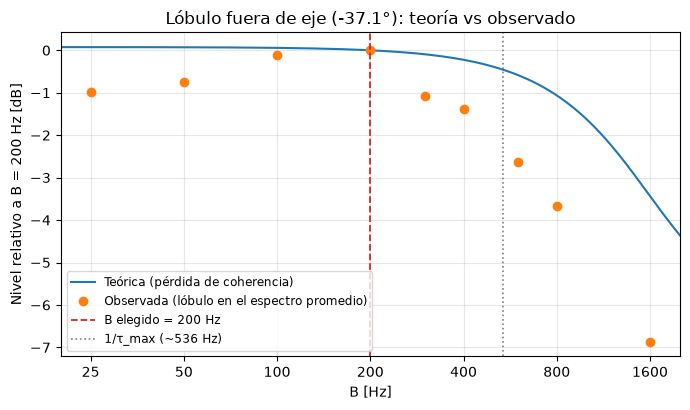


Ancho -3 dB con T_bloque = 0.1 s : 14.43° a 16.14° (rango 1.71°)
Ancho -3 dB con L = 40 fijo     : 14.43° a 16.39° (rango 1.96°)


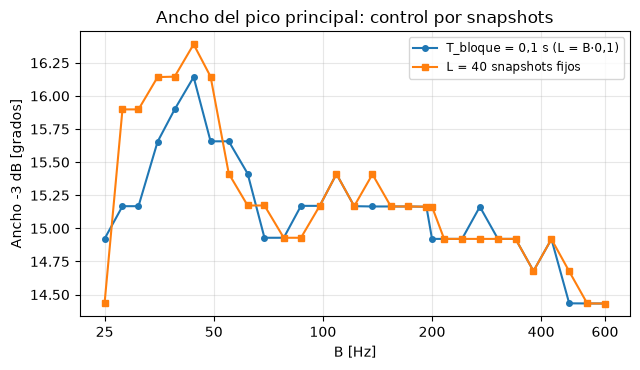

In [7]:
# ---------------------------------------------------------------
# Poner esta celda DESPUÉS de la celda del barrido de B. Reemplaza a
# celda_lobulo_fuera_de_eje.py.
# Usa: resultados, evaluar_B, theta, B_LISTA, B_ELEGIDO, B_LIM_NB, pos, SUB,
#      c, lam, d, NFFT_ESP, T_BLOQUE
# ---------------------------------------------------------------

# 1) Rangos exactos de las métricas del pico principal (para citar en el texto)
Bs_arr = np.array([r[0] for r in resultados])
anchos = np.array([r[3] for r in resultados])
contr = np.array([r[4] for r in resultados])
i_max, i_min = anchos.argmax(), anchos.argmin()
j_max, j_min = contr.argmax(), contr.argmin()
paso_ang = np.degrees(np.arcsin(lam / (NFFT_ESP * d)))   # paso de la grilla angular en broadside

print(f"Ancho -3 dB : máx {anchos[i_max]:.2f}° (B={Bs_arr[i_max]} Hz) | mín {anchos[i_min]:.2f}° (B={Bs_arr[i_min]} Hz) "
      f"| rango {anchos.max() - anchos.min():.2f}°")
print(f"Contraste   : máx {contr[j_max]:.2f} dB (B={Bs_arr[j_max]} Hz) | mín {contr[j_min]:.2f} dB (B={Bs_arr[j_min]} Hz) "
      f"| rango {contr.max() - contr.min():.2f} dB")
print(f"Paso de la grilla angular en broadside ≈ {paso_ang:.2f}°\n")

# 2) Pérdida de coherencia por banda ancha (teórica, solo depende de la geometría)
#    Fuente plana en ang_off con espectro plano en [-B/2, B/2], beamformer de fase apuntado a ella a Fc:
#    pérdida(B) = 10*log10( promedio_delta |(1/K) * sum_k exp(-j*2*pi*delta*tau_k)|^2 )
UMBRAL_DB = 1.0
B_REF = [25, 50, 100]
curva_ref = np.mean([evaluar_B(b)[4] for b in B_REF], axis=0)
zona_off = (theta >= -60) & (theta <= -20)
ang_off = theta[zona_off][np.argmax(curva_ref[zona_off])]     # ángulo del lóbulo fuera de eje
sel_off = np.abs(theta - ang_off) <= 3.0

x_s = pos[SUB] - pos[SUB].mean()
tau_k = x_s * np.sin(np.radians(ang_off)) / c
tau_ext = tau_k.max() - tau_k.min()                            # retardo entre extremos


def perdida_coherencia_dB(B_val, n_f=401):
    delta = np.linspace(-B_val / 2, B_val / 2, n_f)
    coh = np.abs(np.exp(-2j * np.pi * np.outer(delta, tau_k)).mean(axis=1)) ** 2
    return 10 * np.log10(coh.mean())


# Comparación con lo observado en el espectro espacial promedio
B_COMP = np.array([25, 50, 100, 200, 300, 400, 600, 800, 1600])
lobulo = np.array([evaluar_B(int(b))[4][sel_off].max() for b in B_COMP])   # nivel relativo al pico principal
teoria = np.array([perdida_coherencia_dB(b) for b in B_COMP])
i_ref = int(np.argmin(np.abs(B_COMP - B_ELEGIDO)))
obs_rel = lobulo - lobulo[i_ref]          # observado, respecto de B elegido
teo_rel = teoria - teoria[i_ref]          # teórico, respecto de B elegido

print(f"Lóbulo fuera de eje en {ang_off:.1f}° | retardo entre extremos = {tau_ext * 1e3:.2f} ms")
print(f"{'B [Hz]':>7} {'B*tau':>6} {'pérd. teórica':>14} {'teór. vs 200':>13} {'obs. vs 200':>12} {'obs - teór':>11}")
for k, b in enumerate(B_COMP):
    print(f"{b:7d} {b * tau_ext:6.2f} {teoria[k]:14.2f} {teo_rel[k]:13.2f} {obs_rel[k]:12.2f} {obs_rel[k] - teo_rel[k]:11.2f}")

B_fino = np.arange(10, 3001, 10)
perd_fino = np.array([perdida_coherencia_dB(b, 201) for b in B_fino])
idx_lim = np.where(perd_fino < -UMBRAL_DB)[0]
if len(idx_lim):
    print(f"\nLa pérdida teórica supera {UMBRAL_DB:.0f} dB a partir de B ≈ {B_fino[idx_lim[0]]} Hz (B*tau = {B_fino[idx_lim[0]] * tau_ext:.2f})")
print(f"Pérdida teórica en B = {B_ELEGIDO:.0f} Hz: {perdida_coherencia_dB(B_ELEGIDO):.2f} dB")

plt.figure(figsize=(7, 4.2))
plt.semilogx(B_fino, perd_fino - perdida_coherencia_dB(B_ELEGIDO), "-", label="Teórica (pérdida de coherencia)")
plt.semilogx(B_COMP, obs_rel, "o", label="Observada (lóbulo en el espectro promedio)")
plt.axvline(B_ELEGIDO, color="tab:red", linestyle="--", linewidth=1.3, label=f"B elegido = {B_ELEGIDO:.0f} Hz")
plt.axvline(B_LIM_NB, color="gray", linestyle=":", linewidth=1.2, label=f"1/τ_max (~{B_LIM_NB:.0f} Hz)")
plt.xlim(20, 2000)
plt.xticks([25, 50, 100, 200, 400, 800, 1600], ["25", "50", "100", "200", "400", "800", "1600"])
plt.minorticks_off()
plt.xlabel("B [Hz]")
plt.ylabel(f"Nivel relativo a B = {B_ELEGIDO:.0f} Hz [dB]")
plt.title(f"Lóbulo fuera de eje ({ang_off:.1f}°): teoría vs observado")
plt.grid(alpha=0.3)
plt.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

# 3) Control: ancho del pico principal con la MISMA cantidad de snapshots por bloque para todo B
#    (si la mejora aparente a B grande desaparece, venía de la varianza y no de la resolución)
L_FIJO = 40
T_BLOQUE_ORIG = T_BLOQUE
anchos_fijo = []
for B_val in B_LISTA:
    T_BLOQUE = L_FIJO / B_val
    anchos_fijo.append(evaluar_B(B_val)[2])
T_BLOQUE = T_BLOQUE_ORIG
anchos_fijo = np.array(anchos_fijo)

print(f"\nAncho -3 dB con T_bloque = 0.1 s : {anchos.min():.2f}° a {anchos.max():.2f}° (rango {anchos.max() - anchos.min():.2f}°)")
print(f"Ancho -3 dB con L = {L_FIJO} fijo     : {anchos_fijo.min():.2f}° a {anchos_fijo.max():.2f}° "
      f"(rango {anchos_fijo.max() - anchos_fijo.min():.2f}°)")

plt.figure(figsize=(6.5, 3.8))
plt.semilogx(Bs_arr, anchos, "o-", markersize=4, label="T_bloque = 0,1 s (L = B·0,1)")
plt.semilogx(B_LISTA, anchos_fijo, "s-", markersize=4, label=f"L = {L_FIJO} snapshots fijos")
plt.xticks([25, 50, 100, 200, 400, 600], ["25", "50", "100", "200", "400", "600"])
plt.minorticks_off()
plt.xlabel("B [Hz]")
plt.ylabel("Ancho -3 dB [grados]")
plt.title("Ancho del pico principal: control por snapshots")
plt.grid(alpha=0.3)
plt.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

### Configuración y elección del ancho de banda $B$ (2)

Con el código de la celda anterior buscamos el límite superior de $B$ usando la radio AM como fuente de prueba: su lóbulo está fuera de eje ($\theta\approx-37{,}1^\circ$, retardo entre extremos $\tau_{ext}\approx1{,}13\text{ ms}$), así que es sensible a la violación de la hipótesis de banda angosta, a diferencia del pico principal en *broadside*.

**Pérdida de coherencia teórica.** Una componente a $F_c+\delta$ llega con fase $2\pi(F_c+\delta)\tau_k$, pero el *beamformer* compensa solo $2\pi F_c\tau_k$. Para una fuente a $\theta$ con espectro plano en la banda, apuntando el *beamformer* de fase a ella a $F_c$, la pérdida de potencia es
$$
10\log_{10}\left\langle \left|\frac{1}{K}\sum_{k} e^{-j2\pi\delta\tau_k}\right|^2 \right\rangle_{\delta\in[-B/2,\,B/2]},\qquad \tau_k = \frac{x_k\sin\theta}{c}.
$$
Esta pérdida depende solo de la geometría y de $B$. La tabla la compara con la caída observada del lóbulo fuera de eje en el espectro espacial promedio (ambas relativas a $B=200\text{ Hz}$, para poder compararlas):

**Referencia de comparación.** Se debería notar que el nivel del lóbulo fuera de eje respecto del pico principal depende de cuánto más débil es la radio que el locutor, por lo que no es una pérdida en sí misma. Para ver cómo cambia con $B$, lo expresamos relativo a un $B$ de referencia, que tomamos en $B=200\text{ Hz}$ (nivel relativo $=0\text{ dB}$). Lo elegimos como candidato porque se encuentra en la meseta ($100$ a $200\text{ Hz}$) donde tanto la teoría como la observación son planas; es solo una normalización y la decisión final se toma más abajo. Usar $100\text{ Hz}$ como referencia cambia la caída observada en menos de $0{,}15\text{ dB}$ y no modifica el límite que obtenemos. La pérdida teórica de la primera columna es absoluta y no depende de esta referencia.

| $B$ [Hz] | $B\,\tau_{ext}$ | Pérdida teórica [dB] | Teórica vs. 200 Hz [dB] | Observada vs. 200 Hz [dB] |
|---|---|---|---|---|
| 25 | 0,03 | 0,00 | +0,07 | −0,98 |
| 50 | 0,06 | 0,00 | +0,07 | −0,74 |
| 100 | 0,11 | −0,02 | +0,06 | −0,11 |
| 200 | 0,23 | −0,08 | 0,00 | 0,00 |
| 300 | 0,34 | −0,17 | −0,09 | −1,08 |
| 400 | 0,45 | −0,30 | −0,22 | −1,38 |
| 600 | 0,68 | −0,66 | −0,58 | −2,64 |
| 800 | 0,90 | −1,13 | −1,06 | −3,66 |
| 1600 | 1,80 | −3,50 | −3,42 | −6,87 |

**Lectura de los datos.**

- **Teoría:** la pérdida es despreciable hasta $B=200\text{ Hz}$ ($-0{,}08\text{ dB}$), llega a $-0{,}30\text{ dB}$ con $400\text{ Hz}$ y a $-0{,}66\text{ dB}$ con $600\text{ Hz}$, y supera $1\text{ dB}$ recién a partir de $B\approx750\text{ Hz}$ ($B\,\tau_{ext}\approx0{,}84$). Esto es consistente con que el efecto aparece cuando $B\,\tau_{ext}$ se acerca a $1$. La línea gris de la figura ($\approx536\text{ Hz}$) es $1/\tau_{max}$ para la apertura completa en *endfire*, el peor caso posible. Para la dirección real de la radio el límite es más alto.
- **Observación:** el nivel del lóbulo se mantiene entre $100$ y $200\text{ Hz}$ ($-0{,}11$ y $0\text{ dB}$) y después cae: $-1{,}08\text{ dB}$ con $300\text{ Hz}$, $-1{,}38\text{ dB}$ con $400\text{ Hz}$, $-2{,}64\text{ dB}$ con $600\text{ Hz}$, $-3{,}66\text{ dB}$ con $800\text{ Hz}$ y $-6{,}87\text{ dB}$ con $1600\text{ Hz}$. Por debajo de $100\text{ Hz}$ el nivel también se aparta cerca de $1\text{ dB}$ ($-0{,}98$ y $-0{,}74\text{ dB}$), coherente con la cota inferior de $\approx100\text{ Hz}$.
- **Teoría vs. observación:** ambas caen al aumentar $B$, pero la observada cae más y la diferencia crece con $B$ ($-0{,}99\text{ dB}$ con $300\text{ Hz}$, $-2{,}06$ con $600$, $-3{,}44$ con $1600\text{ Hz}$). Una parte del efecto es que la FFT espacial supone la fase de $F_c$: una componente a $F_c+\delta$ se ve como proveniente de un ángulo aparente $\sin\theta_{ap}=\sin\theta\,(1+\delta/F_c)$, así que la fuente se reparte en un abanico de ancho $\pm\sin\theta\,B/(2F_c)$ y, como el espectro de la fuente decae con la frecuencia, el centro del abanico se corre hacia $0^\circ$. Con estos datos no podemos atribuir la diferencia restante a una causa en particular (por ejemplo, al contenido espectral de la fuente), y el salto de $200$ a $300\text{ Hz}$ es más brusco que el resto, por lo que usamos los $300\text{ Hz}$ como orden de magnitud y no como valor exacto.

**Límite superior.** Con el criterio de $1\text{ dB}$ obtenemos dos valores. La teoría da $B\approx750\text{ Hz}$, que consideramos una cota máxima absoluta. La observación da $B\approx300\text{ Hz}$, porque ahí el lóbulo ya cae $1{,}08\text{ dB}$ respecto de $200\text{ Hz}$. Como la caída observada es mayor que la teórica y no sabemos explicar la diferencia, nos quedamos con el criterio más exigente. Combinado con la cota inferior de $\approx100\text{ Hz}$ (primera parte), el rango razonable es $100\text{--}300\text{ Hz}$.

**Decisión.** Elegimos $B = 200\text{ Hz}$: está dentro de ese rango, en la meseta donde el lóbulo todavía no cae ($100$ a $200\text{ Hz}$), la pérdida de coherencia teórica es despreciable ($-0{,}08\text{ dB}$) y entrega $L = 20$ *snapshots* por bloque. Es una elección conservadora: valores entre $100$ y $300\text{ Hz}$ serían igualmente defendibles, por lo que el valor exacto no es crítico. En la Pregunta 2 esto da $L=159$ *snapshots* en la zona de $0{,}8\text{ s}$, muy por encima de $2K=18$ para estimar $\hat{\mathbf{R}}_{i+n}$.

## Espectrograma de frecuencia espacial e identificación de las señales

Demodulamos la señal con $B = 200\text{ Hz}$ y graficamos el espectrograma espacial (con ventana de Hamming sobre los sensores). Como unos pocos picos muy intensos cerca de $0\text{ dB}$ oscurecerían el resto de la imagen, ajustamos el rango de color al percentil $99{,}5$ (`extend="max"`) y lo acompañamos del espectro espacial promedio global para ubicar con claridad los picos direccionales.

Diezmado x80: Fs2 = 200 Hz, muestras = 6794, snapshots/bloque = 20


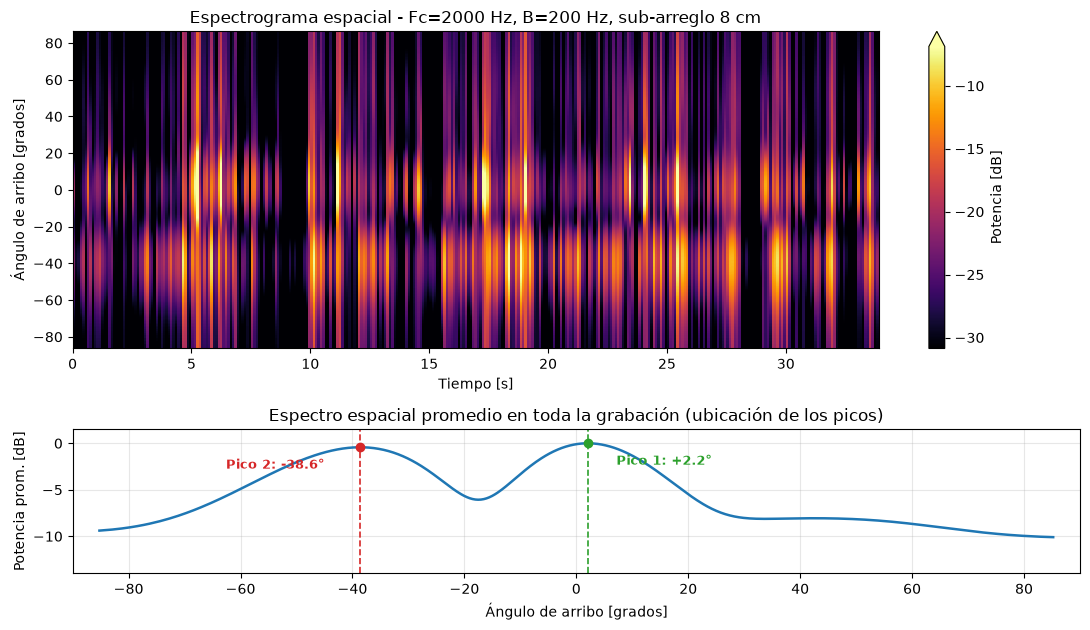

Picos principales detectados:
  Pico 1: theta =    2.2°  ->    0.0 dB
  Pico 2: theta =  -38.6°  ->   -0.4 dB


In [10]:
B = B_ELEGIDO
xd, Fs2 = demodular(B)
P_esp, L = espectro_por_bloque(xd, Fs2, ventana=np.hamming(K))
nb = P_esp.shape[1]
print(f"Diezmado x{int(Fs // B)}: Fs2 = {Fs2:.0f} Hz, muestras = {xd.shape[1]}, snapshots/bloque = {L}")

P_vis = P_esp[visible, :]
P_dB = 10 * np.log10(P_vis + 1e-12)
P_dB -= P_dB.max()
t_blk = (np.arange(nb) + 0.5) * T_BLOQUE

Pm_all = 10 * np.log10(P_vis.mean(axis=1) + 1e-12)
Pm_all -= Pm_all.max()
picos, _ = signal.find_peaks(Pm_all, prominence=1.0)
picos_ord = picos[np.argsort(Pm_all[picos])[::-1]]

# Rango de color ajustado al percentil 99.5 para que ambas bandas sean nítidas y no quede oscuro
vmax_esp = float(np.percentile(P_dB, 99.5))
vmin_esp = vmax_esp - 24.0

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), gridspec_kw={"height_ratios": [2.2, 1]})
im = axes[0].pcolormesh(t_blk, theta, P_dB, shading="auto", vmin=vmin_esp, vmax=vmax_esp, cmap="inferno")
fig.colorbar(im, ax=axes[0], extend="max", label="Potencia [dB]")
axes[0].set_xlabel("Tiempo [s]")
axes[0].set_ylabel("Ángulo de arribo [grados]")
axes[0].set_title(f"Espectrograma espacial - Fc={Fc:.0f} Hz, B={B:.0f} Hz, sub-arreglo {ELEGIDO}")

axes[1].plot(theta, Pm_all, linewidth=1.8, color="tab:blue")
for i_pk, pk in enumerate(picos_ord[:2]):
    col = "tab:green" if i_pk == 0 else "tab:red"
    axes[1].axvline(theta[pk], color=col, linestyle="--", linewidth=1.2)
    axes[1].plot(theta[pk], Pm_all[pk], "o", color=col)
    axes[1].annotate(f"Pico {i_pk+1}: {theta[pk]:+.1f}°", xy=(theta[pk], Pm_all[pk]),
                     xytext=(theta[pk] + (5 if i_pk == 0 else -24), Pm_all[pk] - 2.3),
                     fontsize=9.5, fontweight="bold", color=col)
axes[1].set_xlim(-90, 90)
axes[1].set_ylim(-14, 1.5)
axes[1].set_xlabel("Ángulo de arribo [grados]")
axes[1].set_ylabel("Potencia prom. [dB]")
axes[1].set_title("Espectro espacial promedio en toda la grabación (ubicación de los picos)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Picos principales detectados:")
for i_pk, pk in enumerate(picos_ord):
    print(f"  Pico {i_pk+1}: theta = {theta[pk]:6.1f}°  ->  {Pm_all[pk]:5.1f} dB")

In [11]:
# Audios direccionales (DAS banda ancha) para identificar qué señal proviene de cada pico
def guardar_y_mostrar_audio(titulo, sig, nombre_wav, t_clip_ini=12.0, t_clip_fin=24.0):
    sig_norm = sig / (np.max(np.abs(sig)) + 1e-12)
    ruta = os.path.join("audios", nombre_wav)
    wavfile.write(ruta, Fs, np.round(sig_norm * 28000.0).astype(np.int16))
    if t_clip_ini is None or t_clip_fin is None:
        clip = sig_norm
        etiqueta = f"completo {len(sig)/Fs:.2f} s"
    else:
        i0, i1 = int(t_clip_ini * Fs), int(t_clip_fin * Fs)
        clip = sig_norm[i0:i1]
        etiqueta = f"reproductor: {t_clip_ini:.1f}-{t_clip_fin:.1f} s"
    print(f"{titulo}  [guardado en {ruta}, {etiqueta}]")
    display(Audio(clip, rate=Fs))

def das_banda_ancha(theta_deg):
    X_f = np.fft.rfft(xs, axis=1)
    freqs = np.fft.rfftfreq(N, 1.0 / Fs)
    fase = np.exp(2j * np.pi * freqs[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_deg)) / c))
    return np.fft.irfft(np.mean(X_f * fase, axis=0), n=N)

ang_p1, ang_p2 = theta[picos_ord[0]], theta[picos_ord[1]]
y_das_p1 = das_banda_ancha(ang_p1)
y_das_p2 = das_banda_ancha(ang_p2)

guardar_y_mostrar_audio("1) Micrófono central sin procesar (canal 7)", x[7], "01_mic_central.wav")
guardar_y_mostrar_audio(f"2) Beamformer DAS apuntado al Pico 1 ({ang_p1:+.1f}°) -> Locutor", y_das_p1, "02_das_pico1.wav")
guardar_y_mostrar_audio(f"3) Beamformer DAS apuntado al Pico 2 ({ang_p2:+.1f}°) -> Radio AM", y_das_p2, "03_das_pico2.wav")

1) Micrófono central sin procesar (canal 7)  [guardado en audios\01_mic_central.wav, reproductor: 12.0-24.0 s]


2) Beamformer DAS apuntado al Pico 1 (+2.2°) -> Locutor  [guardado en audios\02_das_pico1.wav, reproductor: 12.0-24.0 s]


3) Beamformer DAS apuntado al Pico 2 (-38.6°) -> Radio AM  [guardado en audios\03_das_pico2.wav, reproductor: 12.0-24.0 s]


### ¿Qué señales espaciales se observan?

Combinando el espectrograma espacial, el espectro promedio y la escucha de los haces direccionales (todo a $F_c = 2000\text{ Hz}$ y $B = 200\text{ Hz}$) se pueden identificar 4 componentes espaciales diferentes:

1. **Pico 1 ($\approx +2{,}2^\circ$, intermitente) — Locutor (señal deseada):** aparece en ráfagas energéticas separadas por pausas de silencio; al apuntar el *beamformer* DAS en esa dirección se escucha claramente la voz principal. Más específicamente, la voz se escucha más claramente que en el micrófono central, pero todavía se oye la radio de fondo.
2. **Pico 2 ($\approx -38{,}6^\circ$, continuo) — Radio AM (interferencia direccional):** forma una banda horizontal sostenida a lo largo de los $34\text{ s}$. Al apuntar allí se oye más nítidamente la transmisión de radio continua, pero igualmente se nota mucho la voz del locutor, que interfiere bastante con la transmisión. En el espectro promedio de toda la grabación queda a solo $0{,}4\text{ dB}$ por debajo del pico del locutor, es decir, es una interferencia de potencia comparable a la señal deseada en esta banda.
3. **Piso difuso en todo $[-90^\circ, 90^\circ]$ — Coolers:** ruido de fondo estacionario repartido en múltiples direcciones. Al analizar una sola banda de frecuencia, puede subestimar a los coolers si su energía se concentra en frecuencias más bajas.
4. **Reverberancia:** réplicas atenuadas de la voz que llegan desde otras direcciones y que, a diferencia de los coolers, siguen el patrón temporal del habla. En el gráfico del barrido de $B$ se ven lóbulos menores en $\approx -17^\circ$, $+35^\circ$ y $+60^\circ$, con niveles de $\approx -7$ a $-10\text{ dB}$ para $B = 200\text{ Hz}$ (valores leídos del gráfico), que no fueron detectados como picos (prominencia $\geq 1\text{ dB}$) en el espectro promedio de toda la grabación. Pueden corresponder a reflexiones o a lóbulos laterales del propio arreglo, y con estos gráficos no se pueden distinguir.

Los ángulos se miden respecto de la dirección perpendicular al arreglo (*broadside*). Un arreglo lineal no distingue $\theta$ de $180^\circ-\theta$, y el signo depende de la orientación del arreglo y de la convención de la FFT espacial.

*Nota:* la dirección de la radio aparece con tres valores en este TP: $-38{,}6^\circ$ (pico del espectro promedio de toda la grabación), $-37{,}1^\circ$ (lóbulo del barrido de $B$) y $-38{,}75^\circ$ (refinado en la Pregunta 2 con los bloques de silencio vocal). Las diferencias son menores que $2^\circ$, mucho menores que el ancho del haz ($\approx 15^\circ$).

# Pregunta 2 — Beamformer óptimo SMI

En esta sección seleccionamos una ventana de interferencia y ruido para estimar el *beamformer* óptimo **SMI** y luego graficar su patrón beam.


Para encontrar el *beamformer* óptimo **SMI** tenemos que encontrar un *beamformer* que resuelva estas ecuaciones:

$$\mathbf{w}_{\text{SMI}} = \frac{\hat{\mathbf{R}}_{i+n}^{-1}\mathbf{v}(\theta_s)}{\mathbf{v}(\theta_s)^H \hat{\mathbf{R}}_{i+n}^{-1}\mathbf{v}(\theta_s)}, \qquad \hat{\mathbf{R}}_{i+n} = \frac{1}{L_{in}}\mathbf{X}_{i+n}\mathbf{X}_{i+n}^H$$

Se debería notar que $[\mathbf{v}(\theta)]_k$  es el *steering vector* y es igual a:

 $[\mathbf{v}(\theta)]_k = e^{-j\frac{2\pi d}{\lambda} k \sin\theta}$.

Para estimar $\hat{\mathbf{R}}_{i+n}$ de forma confiable, necesitamos:
1. Contar con al menos $L_{in} \ge 2K = 18$ *snapshots* (regla de Reed–Mallett–Brennan, 1974).
2. **Ausencia de voz del locutor** (fuente deseada) para evitar *self-nulling* —es decir, que la matriz de covarianza incluya energía desde $\theta_s$ y el *beamformer* termine atenuando o poniendo un nulo parcial sobre la propia señal deseada—, pero con **interferencia de radio AM bien presente** para que $\hat{\mathbf{R}}_{i+n}$ capture fielmente su dirección y estructura espacial.

Buscamos entonces una pausa vocal verificada en $300\text{--}3500\text{ Hz}$ donde la radio AM sea particularmente intensa tanto en banda ancha como en $F_c = 2000\text{ Hz}$.


Ángulo refinado del locutor: theta_s = 1.25° (83 bloques activos)
Ángulo refinado de radio AM: theta_i = -38.75° (101 bloques de silencio vocal)
Zona continua elegida: [17.6, 18.4] s -> L = 159 snapshots (>> 2K = 18), cond(R) = 323.9


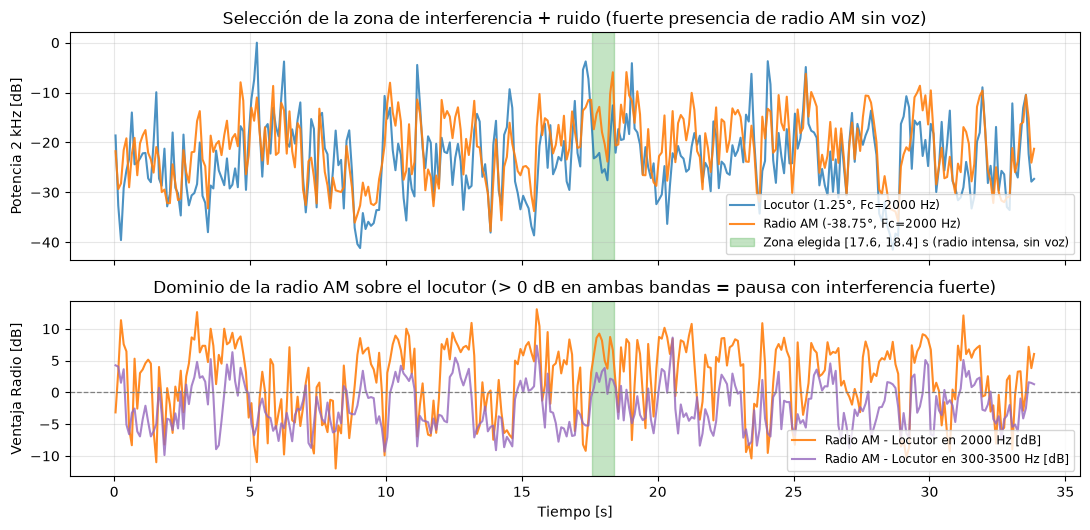

4) Audio de la zona elegida [17.6, 18.4] s (solo interferencia intensa + ruido, canal 7)  [guardado en audios\04_zona_interferencia_17.6_18.4s.wav, completo 0.80 s]


In [13]:
def steering(theta_deg):
    k_idx = np.arange(K)[:, None]
    th = np.atleast_1d(theta_deg)[None, :]
    return np.exp(-1j * 2 * np.pi * d * np.sin(np.radians(th)) / lam * k_idx)

# Potencia en banda vocal (300-3500 Hz) para identificar pausas reales sin voz
sos_voc = signal.butter(4, [300, 3500], btype="band", fs=Fs, output="sos")
e1_bb = signal.sosfiltfilt(sos_voc, y_das_p1) ** 2
e2_bb = signal.sosfiltfilt(sos_voc, y_das_p2) ** 2
Ls = int(T_BLOQUE * Fs)

p1_bb = np.array([e1_bb[b * Ls:(b + 1) * Ls].mean() for b in range(nb)])
p2_bb = np.array([e2_bb[b * Ls:(b + 1) * Ls].mean() for b in range(nb)])
p1_bb_dB = 10 * np.log10(p1_bb + 1e-12)
p2_bb_dB = 10 * np.log10(p2_bb + 1e-12)
rat_bb_dB = p1_bb_dB - p2_bb_dB

bloques_voz = (rat_bb_dB > 3.0) & (p1_bb_dB > np.percentile(p1_bb_dB, 75))
bloques_int = (rat_bb_dB < 0.0) & (p1_bb_dB < np.percentile(p1_bb_dB, 40))

angles = np.linspace(-90, 90, 721)
V_grid = steering(angles)

X_voz = np.hstack([xd[:, b * L:(b + 1) * L] for b in range(nb) if bloques_voz[b]])
X_int = np.hstack([xd[:, b * L:(b + 1) * L] for b in range(nb) if bloques_int[b]])

theta_s = angles[np.argmax(np.mean(np.abs(V_grid.conj().T @ X_voz) ** 2, axis=1))]
theta_i = angles[np.argmax(np.mean(np.abs(V_grid.conj().T @ X_int) ** 2, axis=1))]
print(f"Ángulo refinado del locutor: theta_s = {theta_s:.2f}° ({bloques_voz.sum()} bloques activos)")
print(f"Ángulo refinado de radio AM: theta_i = {theta_i:.2f}° ({bloques_int.sum()} bloques de silencio vocal)")

# Potencia en Fc = 2000 Hz en ambas direcciones para visualizar la interferencia en la banda del SMI
v_s0 = steering(theta_s)[:, 0] / K
v_i0 = steering(theta_i)[:, 0] / K
p1_2k_dB = 10 * np.log10(np.array([np.mean(np.abs(v_s0.conj() @ xd[:, b * L:(b + 1) * L]) ** 2) for b in range(nb)]) + 1e-12)
p2_2k_dB = 10 * np.log10(np.array([np.mean(np.abs(v_i0.conj() @ xd[:, b * L:(b + 1) * L]) ** 2) for b in range(nb)]) + 1e-12)

# Zona continua libre de voz con la radio AM más intensa de toda la grabación: [17.6, 18.4] s
t_ini, t_fin = 17.6, 18.4
X_zona = xd[:, int(t_ini * Fs2):int(t_fin * Fs2)]
L_zona = X_zona.shape[1]
R_zona = (X_zona @ X_zona.conj().T) / L_zona
print(f"Zona continua elegida: [{t_ini}, {t_fin}] s -> L = {L_zona} snapshots (>> 2K = {2*K}), cond(R) = {np.linalg.cond(R_zona):.1f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ref_2k = max(p1_2k_dB.max(), p2_2k_dB.max())
axes[0].plot(t_blk, p1_2k_dB - ref_2k, label=f"Locutor ({theta_s:.2f}°, Fc=2000 Hz)", alpha=0.8)
axes[0].plot(t_blk, p2_2k_dB - ref_2k, label=f"Radio AM ({theta_i:.2f}°, Fc=2000 Hz)", alpha=0.9)
axes[0].axvspan(t_ini, t_fin, color="tab:green", alpha=0.28, label=f"Zona elegida [{t_ini}, {t_fin}] s (radio intensa, sin voz)")
axes[0].set_ylabel("Potencia 2 kHz [dB]")
axes[0].set_title("Selección de la zona de interferencia + ruido (fuerte presencia de radio AM sin voz)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.3)

axes[1].plot(t_blk, p2_2k_dB - p1_2k_dB, color="tab:orange", label="Radio AM - Locutor en 2000 Hz [dB]", alpha=0.9)
axes[1].plot(t_blk, p2_bb_dB - p1_bb_dB, color="tab:purple", label="Radio AM - Locutor en 300-3500 Hz [dB]", alpha=0.8)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.9)
axes[1].axvspan(t_ini, t_fin, color="tab:green", alpha=0.28)
axes[1].set_xlabel("Tiempo [s]")
axes[1].set_ylabel("Ventaja Radio [dB]")
axes[1].set_title("Dominio de la radio AM sobre el locutor (> 0 dB en ambas bandas = pausa con interferencia fuerte)")
axes[1].legend(loc="lower right", fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

guardar_y_mostrar_audio(
    f"4) Audio de la zona elegida [{t_ini}, {t_fin}] s (solo interferencia intensa + ruido, canal 7)",
    x[7, int(t_ini * Fs):int(t_fin * Fs)], "04_zona_interferencia_17.6_18.4s.wav",
    t_clip_ini=None, t_clip_fin=None
)

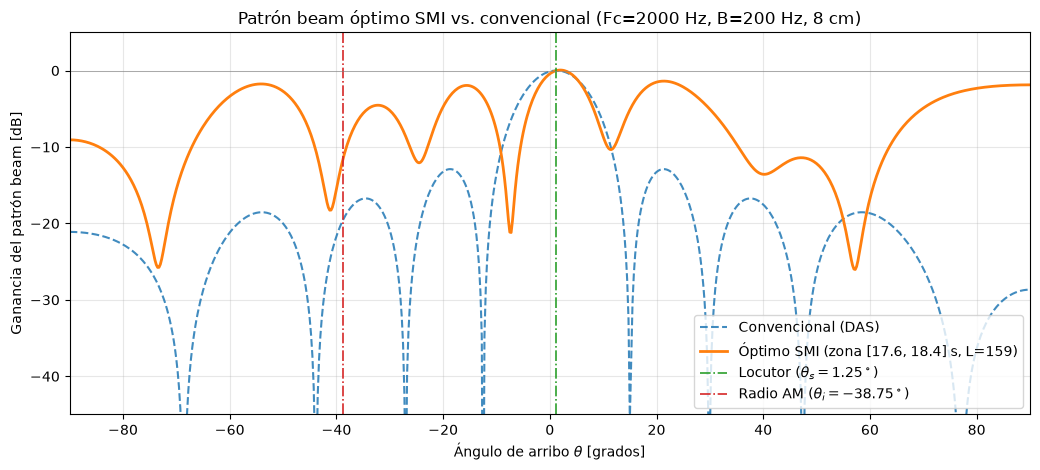

Beamformer                 G(th_s)   G(th_i)   Nulo mín cerca th_i  WNG [dB]  Voz/Int [dB]
DAS convencional             0.00    -19.54      -53.45 (@-43.8°)      9.54        12.66
SMI [17.6, 18.4] s           0.00    -11.55      -18.27 (@-41.2°)      4.81        15.46
Ventaja radio en la zona: 7.3 dB (2 kHz) | 1.9 dB (300-3500 Hz)
Voz/Int fuera de la zona, DAS: 12.69 dB
Voz/Int fuera de la zona, SMI: 15.40 dB


In [14]:
# Estimación del beamformer óptimo SMI vs. convencional DAS
vs = steering(theta_s)[:, 0]
w_das = vs / K
R_inv = np.linalg.inv(R_zona)
w_smi = (R_inv @ vs) / (vs.conj() @ R_inv @ vs)

bp_das = 20 * np.log10(np.abs(w_das.conj() @ V_grid) + 1e-12)
bp_smi = 20 * np.log10(np.abs(w_smi.conj() @ V_grid) + 1e-12)

plt.figure(figsize=(10.5, 4.8))
plt.plot(angles, bp_das, "--", label="Convencional (DAS)", alpha=0.85)
plt.plot(angles, bp_smi, linewidth=2.0, label=f"Óptimo SMI (zona [{t_ini}, {t_fin}] s, L={L_zona})")
plt.axvline(theta_s, color="tab:green", linestyle="-.", linewidth=1.2, label=rf"Locutor ($\theta_s={theta_s:.2f}^\circ$)")
plt.axvline(theta_i, color="tab:red", linestyle="-.", linewidth=1.2, label=rf"Radio AM ($\theta_i={theta_i:.2f}^\circ$)")
plt.axhline(0, color="gray", linewidth=0.7, alpha=0.6)
plt.ylim(-45, 5)
plt.xlim(-90, 90)
plt.xlabel(r"Ángulo de arribo $\theta$ [grados]")
plt.ylabel("Ganancia del patrón beam [dB]")
plt.title(f"Patrón beam óptimo SMI vs. convencional (Fc={Fc:.0f} Hz, B={B:.0f} Hz, {ELEGIDO})")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

idx_s = np.argmin(np.abs(angles - theta_s))
idx_i = np.argmin(np.abs(angles - theta_i))
mask_nulo = np.abs(angles - theta_i) <= 5.0

print(f"{'Beamformer':24s} {'G(th_s)':>9} {'G(th_i)':>9} {'Nulo mín cerca th_i':>21} {'WNG [dB]':>9} {'Voz/Int [dB]':>13}")
for nombre, w, bp in [("DAS convencional", w_das, bp_das), (f"SMI [{t_ini}, {t_fin}] s", w_smi, bp_smi)]:
    wng = 10 * np.log10(1.0 / np.sum(np.abs(w) ** 2))
    nulo_min = bp[mask_nulo].min()
    ang_nulo = angles[mask_nulo][np.argmin(bp[mask_nulo])]
    voz_int = 10 * np.log10(np.mean(np.abs(w.conj() @ X_voz) ** 2) / np.mean(np.abs(w.conj() @ X_int) ** 2))
    print(f"{nombre:24s} {bp[idx_s]:8.2f}  {bp[idx_i]:8.2f}  {nulo_min:10.2f} (@{ang_nulo:5.1f}°) {wng:9.2f} {voz_int:12.2f}")

    
# 1) Ventaja de la radio sobre el locutor DENTRO de la zona (para verificar +7,0 y +1,9 dB)
m = (t_blk >= t_ini) & (t_blk < t_fin)
ven_2k = 10*np.log10(np.mean(10**(p2_2k_dB[m]/10)) / np.mean(10**(p1_2k_dB[m]/10)))
ven_bb = 10*np.log10(np.mean(10**(p2_bb_dB[m]/10)) / np.mean(10**(p1_bb_dB[m]/10)))
print(f"Ventaja radio en la zona: {ven_2k:.1f} dB (2 kHz) | {ven_bb:.1f} dB (300-3500 Hz)")

# 2) Voz/Int evaluada FUERA de la zona de entrenamiento
fuera = np.array([not (t_ini <= tb < t_fin) for tb in t_blk])
X_int_fz = np.hstack([xd[:, b*L:(b+1)*L] for b in range(nb) if bloques_int[b] and fuera[b]])
for nombre, w in [("DAS", w_das), ("SMI", w_smi)]:
    vi = 10*np.log10(np.mean(np.abs(w.conj() @ X_voz)**2) / np.mean(np.abs(w.conj() @ X_int_fz)**2))
    print(f"Voz/Int fuera de la zona, {nombre}: {vi:.2f} dB")

### Conclusiones de la Pregunta 2

Resumen de las métricas que imprime el código para el patrón beam:

| Beamformer | $G(\theta_s)$ [dB] | $G(\theta_i)$ [dB] | Mínimo en $\pm5^\circ$ de $\theta_i$ [dB] | WNG [dB] | Voz/Int [dB] | Voz/Int fuera de la zona [dB] |
|---|---|---|---|---|---|---|
| DAS convencional | 0,00 | −19,54 | −53,45 (en el ángulo −43,8°) | 9,54 | 12,66 | 12,69 |
| SMI $[17{,}6,\,18{,}4]\text{ s}$ | 0,00 | −11,55 | −18,27 (en el ángulo −41,2°) | 4,81 | 15,46 | 15,40 |

- **Zona con interferencia intensa y sin voz:** En $[17{,}6,\, 18{,}4]\text{ s}$ (franja verde de la figura de selección) la radio AM supera al locutor en promedio por $+7{,}3\text{ dB}$ a $2000\text{ Hz}$ y por $+1{,}9\text{ dB}$ en banda vocal, es decir, es una pausa con interferencia fuerte en ambas bandas. La zona aporta $L = 159$ *snapshots* ($\gg 2K = 18$) con $\text{cond}(\hat{\mathbf{R}}_{i+n}) = 323{,}9$. Escogimos esta zona porque la voz está casi ausente o a un nivel muy bajo, por lo que el riesgo de cancelar la voz con el *beamformer* (*self-nulling*) es reducido.
- **Estructura del patrón (figura):** Ambos *beamformers* mantienen exactamente $0{,}00\text{ dB}$ en $\theta_s = 1{,}25^\circ$. El DAS tiene el patrón convencional de un arreglo uniforme: lóbulo principal de $\approx 12{,}8^\circ$ a $-3\text{ dB}$ y lóbulos laterales entre $\approx -12{,}8$ y $-18{,}6\text{ dB}$. El SMI tiene un lóbulo principal más angosto ($\approx 9{,}6^\circ$), pero lóbulos laterales de $\approx -1{,}3$ a $-4{,}5\text{ dB}$ en varios ángulos ($\approx -54^\circ$, $-32^\circ$, $-16^\circ$, $+21^\circ$; $\approx -1{,}9\text{ dB}$ hacia $+90^\circ$) y nulos angostos en $\approx -73{,}5^\circ$, $-41{,}2^\circ$, $-24{,}6^\circ$, $-7{,}5^\circ$, $+11{,}2^\circ$ y $+57{,}0^\circ$ (profundidades de $-10$ a $-26\text{ dB}$). Todos los valores del patrón, salvo los de la tabla y el nulo de $-41{,}2^\circ$, están leídos del gráfico ($\pm0{,}5\text{ dB}$, $\pm1^\circ$). Como se puede ver en la figura, el SMI coloca nulos donde $\hat{\mathbf{R}}_{i+n}$ tiene energía, que es lo que busca (minimizar la potencia de interferencia y ruido a la salida), aunque eso no implica un nulo profundo en una dirección puntual.
- **Atenuación de la radio AM:** En $\theta_i = -38{,}75^\circ$ el SMI atenúa $-11{,}55\text{ dB}$, menos que el DAS ($-19{,}54\text{ dB}$). El mínimo del SMI dentro de $\pm5^\circ$ de $\theta_i$ es $-18{,}27\text{ dB}$ en $-41{,}2^\circ$, desplazado $\approx 2{,}5^\circ$ de $\theta_i$, mientras que el DAS tiene $-53{,}45\text{ dB}$ en $-43{,}8^\circ$, por la posición de un nulo de su patrón convencional. Por lo tanto, el SMI no anula la radio mejor que el DAS. Una posible razón (no verificada) es que la radio llega por varios caminos (camino directo y reflexiones), por lo que su energía en $\hat{\mathbf{R}}_{i+n}$ está repartida entre varias direcciones y no concentrada en $\theta_i$; como el SMI minimiza la potencia total de salida, reparte la atenuación entre esas direcciones en lugar de concentrar un nulo profundo en $\theta_i$. Otra posibilidad es que $\theta_i$ se haya estimado con un haz de $\approx 15^\circ$ de ancho, y que la dirección dominante de la radio en la zona esté en realidad más cerca de $-41^\circ$.
- **Mejora de la relación voz/interferencia:** Sube de $12{,}66\text{ dB}$ (DAS) a $15{,}46\text{ dB}$ (SMI), es decir $+2{,}80\text{ dB}$. Se debería notar que para estimar esta relación el código calcula, para cada *beamformer*, la potencia media a la salida $\overline{|\mathbf{w}^H\mathbf{x}|^2}$ sobre los *snapshots* de dos conjuntos de bloques de $0{,}1\text{ s}$: los bloques con voz ($83$), donde la salida del DAS apuntado al Pico 1 supera en más de $3\text{ dB}$ a la del Pico 2 en $300$–$3500\text{ Hz}$ y está en el $25\%$ de mayor potencia, y los bloques de silencio vocal ($101$), donde esa diferencia es menor a $0\text{ dB}$ y la potencia del Pico 1 está en el $40\%$ más bajo. Después cuando el codigo ya tiene la estimación de la potencia de la voz y la potencia del ruido simplemente divide ambos resultados para obtener la relación entre la voz y la interferencia. La relación voz/interferencia es el cociente entre ambas potencias, en dB. Evaluada solo sobre bloques de silencio vocal fuera de la zona de entrenamiento, sube de $12{,}69$ a $15{,}40\text{ dB}$ ($+2{,}71\text{ dB}$), prácticamente igual, por lo que la mejora no depende de haber estimado $\hat{\mathbf{R}}_{i+n}$ con esos bloques. Dado lo anterior, esta mejora no proviene de anular la radio, sino de reducir la potencia total de interferencia y ruido de los bloques de silencio vocal, probablemente por la supresión de componentes reverberantes y de los *coolers*, lo que no se comprobó por separado. Es una medida aproximada (el numerador incluye también interferencia) y no demuestra que el *beamformer* funcione igual con una interferencia de estructura espacial distinta.
- **Costo en robustez:** La *White Noise Gain* baja de $9{,}54\text{ dB}$ (DAS, $=10\log_{10}K$) a $4{,}81\text{ dB}$ ($-4{,}73\text{ dB}$). Sigue siendo positiva, así que no amplifica el ruido incorrelado respecto de un solo sensor, pero el patrón queda adaptado a la zona de entrenamiento: una interferencia con otra estructura espacial pasaría con ganancia de entre $-1{,}3$ y $-4{,}5\text{ dB}$ en varios ángulos. La interferencia residual es consistente con el campo difuso de los *coolers* y la reverberancia, que no pueden anularse con unos pocos nulos angostos.

**Resumen.** El DAS tiene el patrón clásico de un arreglo uniforme, con lóbulos laterales bajos y regulares, mientras que el SMI mantiene la ganancia unitaria hacia el locutor, afina el lóbulo principal y pone nulos angostos solo donde la zona de entrenamiento tenía energía, a costa de lóbulos laterales mucho más altos y de menor robustez (menos *White Noise Gain*). En la dirección de la radio AM el SMI no atenúa mejor que el DAS, porque su nulo cae levemente corrido, probablemente por la reverberancia y la resolución limitada del ángulo estimado. Aun así, mejora de forma moderada la relación voz/interferencia, incluso fuera de la zona de entrenamiento, al reducir en conjunto la radio, la reverberancia y los *coolers* y no con un único nulo sobre la radio, aunque esto no se comprobó por separado. Por eso el SMI rinde más cuando la interferencia es estacionaria y está bien representada por la zona elegida, y el DAS es más predecible ante interferencias distintas. Todo esto vale para una sola banda angosta alrededor de $2000\text{ Hz}$ y una única zona de entrenamiento.

# Pregunta 3 (Opcional) — Beamforming óptimo por subbandas con FFT

Procesar solo $200\text{ Hz}$ alrededor de $2000\text{ Hz}$ no alcanza para recuperar una voz inteligible en toda su banda ($300\text{--}3500\text{ Hz}$). Por eso descomponemos los 15 canales con una **STFT** usando ventana **Hamming** de $512$ muestras y **50% de solapamiento** ($256$ muestras, $\Delta f = 31{,}25\text{ Hz} \ll 536\text{ Hz}$), donde cada bin frecuencial actúa como su propia subbanda angosta y la ventana cumple la condición COLA para reconstruir por ISTFT sin artefactos.

Como disponemos de los tres sub-arreglos anidados, en cada bin $f$ elegimos el sub-arreglo de mayor apertura libre de *aliasing* espacial ($d < \lambda/2$):
- **$f \le 1071{,}9\text{ Hz}$:** sub-arreglo de **16 cm** ($7$ sensores, apertura $96\text{ cm}$).
- **$1071{,}9 < f \le 2143{,}8\text{ Hz}$:** sub-arreglo de **8 cm** ($9$ sensores, apertura $64\text{ cm}$).
- **$f > 2143{,}8\text{ Hz}$:** sub-arreglo de **4 cm** ($9$ sensores, apertura $32\text{ cm}$, sin aliasing hasta $4287{,}5\text{ Hz}$).

En cada bin aplicamos SMI con *diagonal loading* ($\delta = 10^{-2}$) usando las tramas de pausa vocal para estimar $\hat{\mathbf{R}}_{i+n}(f)$, y lo comparamos contra el micrófono central sin procesar, DAS por subbandas (8 cm) y SMI por subbandas fijo (8 cm).

In [8]:
NPERSEG = 512
NOVERLAP = NPERSEG // 2
f_stft, t_stft, Z_all = signal.stft(
    x, fs=Fs, window="hamming", nperseg=NPERSEG, noverlap=NOVERLAP, axis=1
)
nF, nT = len(f_stft), len(t_stft)

# Máscaras de evaluación y covarianza en banda vocal (300 - 3500 Hz)
fmask_voz = (f_stft >= 300) & (f_stft <= 3500)
fmask_2k = (f_stft >= 1900) & (f_stft <= 2100)
ff_voz = f_stft[fmask_voz]

v_s_bb = np.exp(-2j * np.pi * ff_voz[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_s)) / c))
v_i_bb = np.exp(-2j * np.pi * ff_voz[None, :] * (pos[SUB][:, None] * np.sin(np.radians(theta_i)) / c))

p_s_t = np.mean(np.abs(np.einsum("kft,kf->ft", Z_all[SUB][:, fmask_voz, :], np.conj(v_s_bb)) / K) ** 2, axis=0)
p_i_t = np.mean(np.abs(np.einsum("kft,kf->ft", Z_all[SUB][:, fmask_voz, :], np.conj(v_i_bb)) / K) ** 2, axis=0)
p_s_t_dB = 10 * np.log10(p_s_t + 1e-12)
rat_t_dB = 10 * np.log10((p_s_t + 1e-12) / (p_i_t + 1e-12))

mask_in_stft = (rat_t_dB < 0.0) & (p_s_t_dB < np.percentile(p_s_t_dB, 40))
mask_voz_stft = (rat_t_dB > 3.0) & (p_s_t_dB > np.percentile(p_s_t_dB, 75))
print(f"STFT: {nF} bines (df={f_stft[1]-f_stft[0]:.2f} Hz), {nT} tramas | Tramas interf.+ruido: {mask_in_stft.sum()}, voz: {mask_voz_stft.sum()}")

def beamformer_subbandas(Z_in, f_bins, sub_fn, mask_in, theta_obj, delta=1e-2, metodo="smi"):
    Y = np.zeros((len(f_bins), Z_in.shape[2]), dtype=complex)
    pesos, subs_usados = [], []
    for fi, freq in enumerate(f_bins):
        sub = sub_fn(freq)
        Km = len(sub)
        Zf = Z_in[sub, fi, :]
        vs_f = np.exp(-2j * np.pi * freq * (pos[sub] * np.sin(np.radians(theta_obj)) / c))

        if metodo == "das" or freq == 0.0:
            w = vs_f / Km
        else:
            Zin = Zf[:, mask_in]
            R = (Zin @ Zin.conj().T) / Zin.shape[1]
            tr = np.real(np.trace(R)) / Km
            R_reg = R + delta * max(tr, 1e-12) * np.eye(Km)
            Rinv_v = np.linalg.solve(R_reg, vs_f)
            w = Rinv_v / (vs_f.conj() @ Rinv_v)

        Y[fi, :] = w.conj() @ Zf
        pesos.append(w)
        subs_usados.append(sub)
    return Y, pesos, subs_usados

f_lim_16 = c / (2 * 0.16)
f_lim_8  = c / (2 * 0.08)
sub_fijo_8 = lambda freq: subarreglos["8 cm"]
sub_anidado = lambda freq: (
    subarreglos["16 cm"] if freq <= f_lim_16 else
    (subarreglos["8 cm"] if freq <= f_lim_8 else subarreglos["4 cm"])
)

Y_raw7 = Z_all[7, :, :]
Y_das8, _, _ = beamformer_subbandas(Z_all, f_stft, sub_fijo_8, mask_in_stft, theta_s, metodo="das")
Y_smi8, _, _ = beamformer_subbandas(Z_all, f_stft, sub_fijo_8, mask_in_stft, theta_s, metodo="smi")
Y_smi_nest, pesos_nest, subs_nest = beamformer_subbandas(
    Z_all, f_stft, sub_anidado, mask_in_stft, theta_s, metodo="smi"
)

def istft_audio(Y_mat):
    _, y_out = signal.istft(Y_mat, fs=Fs, window="hamming", nperseg=NPERSEG, noverlap=NOVERLAP)
    return y_out[:N]

y_das8_t = istft_audio(Y_das8)
y_smi8_t = istft_audio(Y_smi8)
y_nest_t = istft_audio(Y_smi_nest)

guardar_y_mostrar_audio("1) Micrófono central sin procesar", x[7], "01_mic_central.wav")
guardar_y_mostrar_audio("2) DAS por subbandas (8 cm)", y_das8_t, "05_das_subbandas_8cm.wav")
guardar_y_mostrar_audio("3) SMI por subbandas (8 cm)", y_smi8_t, "06_smi_subbandas_8cm.wav")
guardar_y_mostrar_audio("4) SMI por subbandas anidado (16/8/4 cm)", y_nest_t, "07_smi_subbandas_anidado.wav")

print(f"\n{'Método':30s} {'Voz/Int 300-3500 Hz [dB]':>26} {'Voz/Int ~2000 Hz [dB]':>23}")
for nombre, Y_mat in [
    ("Micrófono central sin proc.", Y_raw7),
    ("DAS por subbandas (8 cm)", Y_das8),
    ("SMI por subbandas (8 cm)", Y_smi8),
    ("SMI por subbandas (16/8/4 cm)", Y_smi_nest),
]:
    r_bb = 10 * np.log10(
        np.mean(np.abs(Y_mat[fmask_voz, :][:, mask_voz_stft]) ** 2) /
        np.mean(np.abs(Y_mat[fmask_voz, :][:, mask_in_stft]) ** 2)
    )
    r_2k = 10 * np.log10(
        np.mean(np.abs(Y_mat[fmask_2k, :][:, mask_voz_stft]) ** 2) /
        np.mean(np.abs(Y_mat[fmask_2k, :][:, mask_in_stft]) ** 2)
    )
    print(f"{nombre:30s} {r_bb:26.2f} {r_2k:23.2f}")

STFT: 257 bines (df=31.25 Hz), 2125 tramas | Tramas interf.+ruido: 534, voz: 487


1) Micrófono central sin procesar  [guardado en audios/01_mic_central.wav, reproductor: 12.0-24.0 s]


2) DAS por subbandas (8 cm)  [guardado en audios/05_das_subbandas_8cm.wav, reproductor: 12.0-24.0 s]


3) SMI por subbandas (8 cm)  [guardado en audios/06_smi_subbandas_8cm.wav, reproductor: 12.0-24.0 s]


4) SMI por subbandas anidado (16/8/4 cm)  [guardado en audios/07_smi_subbandas_anidado.wav, reproductor: 12.0-24.0 s]



Método                           Voz/Int 300-3500 Hz [dB]   Voz/Int ~2000 Hz [dB]
Micrófono central sin proc.                         12.56                    5.55
DAS por subbandas (8 cm)                            17.53                   14.10
SMI por subbandas (8 cm)                            18.98                   18.71
SMI por subbandas (16/8/4 cm)                       19.91                   18.71


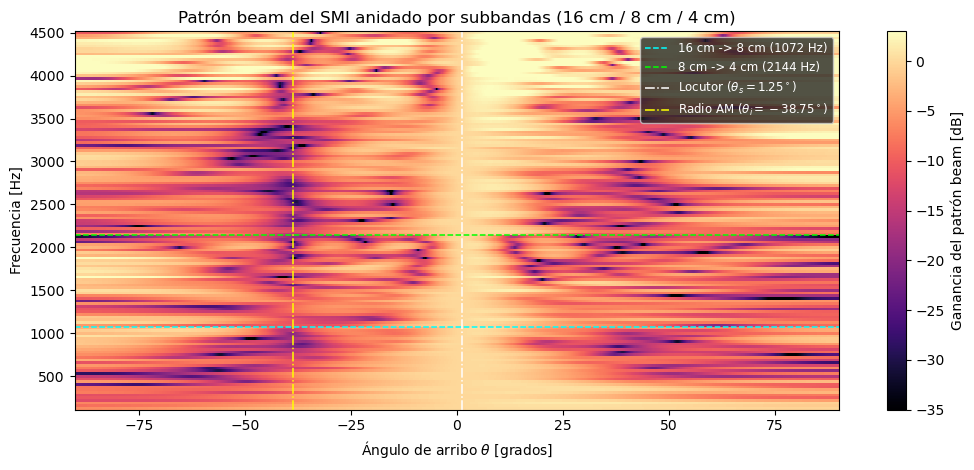

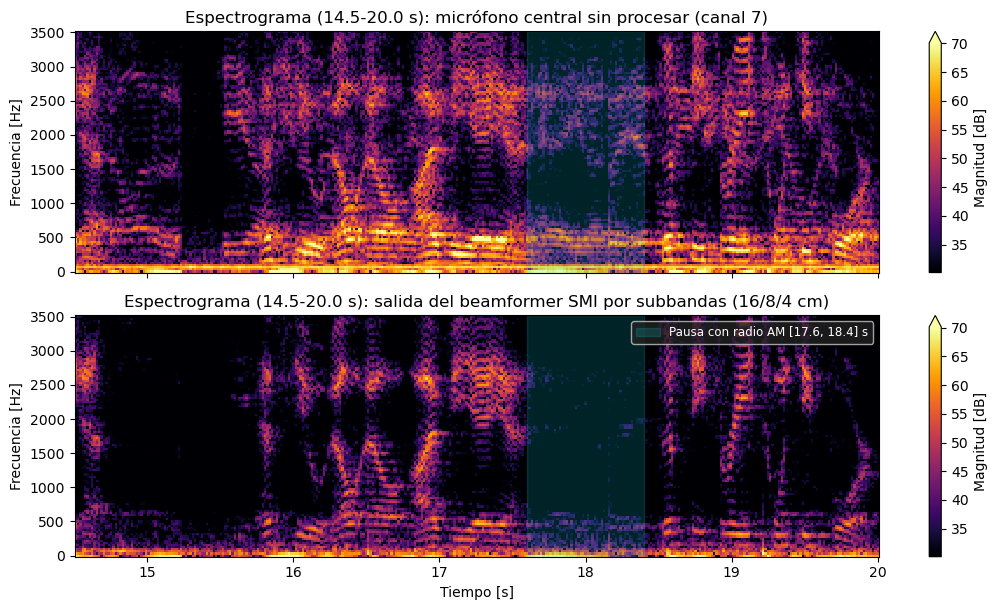

In [9]:
# Patrón beam 2D |B(f, theta)| del SMI anidado
f_plot_mask = (f_stft >= 100) & (f_stft <= 4500)
f_plot_idx = np.where(f_plot_mask)[0]
f_plot = f_stft[f_plot_idx]
BP_2D = np.zeros((len(f_plot_idx), len(angles)))

for row_i, fi in enumerate(f_plot_idx):
    freq = f_stft[fi]
    sub = subs_nest[fi]
    w = pesos_nest[fi]
    V_f = np.exp(-2j * np.pi * freq * (pos[sub][:, None] * np.sin(np.radians(angles[None, :])) / c))
    BP_2D[row_i, :] = 20 * np.log10(np.abs(w.conj() @ V_f) + 1e-12)

plt.figure(figsize=(10.5, 4.8))
plt.pcolormesh(angles, f_plot, BP_2D, shading="auto", vmin=-35, vmax=3, cmap="magma")
plt.colorbar(label="Ganancia del patrón beam [dB]")
plt.axhline(f_lim_16, color="cyan", linestyle="--", linewidth=1.1, label=f"16 cm -> 8 cm ({f_lim_16:.0f} Hz)")
plt.axhline(f_lim_8, color="lime", linestyle="--", linewidth=1.1, label=f"8 cm -> 4 cm ({f_lim_8:.0f} Hz)")
plt.axvline(theta_s, color="white", linestyle="-.", linewidth=1.1, label=rf"Locutor ($\theta_s={theta_s:.2f}^\circ$)")
plt.axvline(theta_i, color="yellow", linestyle="-.", linewidth=1.1, label=rf"Radio AM ($\theta_i={theta_i:.2f}^\circ$)")
plt.xlabel(r"Ángulo de arribo $\theta$ [grados]")
plt.ylabel("Frecuencia [Hz]")
plt.title("Patrón beam del SMI anidado por subbandas (16 cm / 8 cm / 4 cm)")
plt.legend(loc="upper right", fontsize=8.5, facecolor="#222222", framealpha=0.78, labelcolor="white")
plt.tight_layout()
plt.show()

# Comparación legible de espectrogramas tiempo-frecuencia (zoom 14.5 - 20.0 s, 0 - 3500 Hz)
f_spec_mask = f_stft <= 3500
t_spec_mask = (t_stft >= 14.5) & (t_stft <= 20.0)
S_raw = 20 * np.log10(np.abs(Y_raw7[f_spec_mask, :][:, t_spec_mask]) + 1e-12)
S_smi = 20 * np.log10(np.abs(Y_smi_nest[f_spec_mask, :][:, t_spec_mask]) + 1e-12)
vmax_sp = float(np.percentile(S_raw, 99.8))
vmin_sp = vmax_sp - 40.0

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, sharey=True)
im0 = axes[0].pcolormesh(t_stft[t_spec_mask], f_stft[f_spec_mask], S_raw, shading="auto", vmin=vmin_sp, vmax=vmax_sp, cmap="inferno")
fig.colorbar(im0, ax=axes[0], extend="max", label="Magnitud [dB]")
axes[0].axvspan(17.6, 18.4, color="cyan", alpha=0.14)
axes[0].set_ylabel("Frecuencia [Hz]")
axes[0].set_title("Espectrograma (14.5-20.0 s): micrófono central sin procesar (canal 7)")

im1 = axes[1].pcolormesh(t_stft[t_spec_mask], f_stft[f_spec_mask], S_smi, shading="auto", vmin=vmin_sp, vmax=vmax_sp, cmap="inferno")
fig.colorbar(im1, ax=axes[1], extend="max", label="Magnitud [dB]")
axes[1].axvspan(17.6, 18.4, color="cyan", alpha=0.14, label="Pausa con radio AM [17.6, 18.4] s")
axes[1].set_xlabel("Tiempo [s]")
axes[1].set_ylabel("Frecuencia [Hz]")
axes[1].set_title("Espectrograma (14.5-20.0 s): salida del beamformer SMI por subbandas (16/8/4 cm)")
axes[1].legend(loc="upper right", fontsize=8.5, facecolor="#222222", framealpha=0.78, labelcolor="white")

plt.tight_layout()
plt.show()

### Conclusiones de la Pregunta 3 y comparación entre filtros

Comparando los cuatro métodos evaluados en la banda vocal ($300\text{--}3500\text{ Hz}$) y alrededor de $2000\text{ Hz}$:
1. **Micrófono central sin procesar (`12,56 dB` banda ancha / `5,55 dB` en `2 kHz`):** línea base omnidireccional; capta por igual la voz, la radio AM, los *coolers* y el zumbido de $60\text{ Hz}$.
2. **DAS por subbandas 8 cm (`17,53 dB` / `14,10 dB`):** suma **`+4,97 dB`** en banda vocal simplemente al alinear en fase al locutor ($\theta_s = 1{,}25^\circ$) y promediar 9 sensores, reduciendo ruido no correlacionado e interferencias fuera de eje. Sin embargo, su patrón es fijo (no apunta nulos adaptativos), pierde apertura en bajas frecuencias y sufre *aliasing* espacial por encima de $2144\text{ Hz}$.
3. **SMI por subbandas fijo 8 cm (`18,98 dB` / `18,71 dB`):** agrega **`+1,45 dB`** en banda vocal y **`+4,61 dB`** en $2\text{ kHz}$ respecto a DAS al colocar nulos adaptativos sobre la radio AM y las reflexiones correlacionadas en cada bin frecuencial.
4. **SMI por subbandas anidado 16/8/4 cm (`19,91 dB` / `18,71 dB`):** obtiene la mayor mejora global (**`+7,35 dB`** sobre el micrófono central, **`+2,38 dB`** sobre DAS y **`+0,93 dB`** sobre el SMI fijo de 8 cm). Usar el sub-arreglo de $16\text{ cm}$ debajo de $1072\text{ Hz}$ amplía la apertura a $96\text{ cm}$ (clave frente a *coolers* y ruido de bajas frecuencias), mientras que pasar al de $4\text{ cm}$ encima de $2144\text{ Hz}$ evita lóbulos de rejilla.

- **¿Por qué el mínimo del patrón $|B(f, \theta)|$ oscila alrededor de $\theta_i = -38{,}75^\circ$ según la frecuencia?** A diferencia de $\theta_s$ —donde MVDR impone la restricción fija $G(\theta_s) = 0\text{ dB}$ generando una cresta recta en todo $f$—, el SMI no conoce $\theta_i$ a priori sino que minimiza $\mathbf{w}(f)^H \hat{\mathbf{R}}_{i+n}(f)\mathbf{w}(f)$. Debido a la reverberancia del recinto (reflexiones con distinta interferencia constructiva/destructiva según $f$), a los múltiples *coolers* y al *diagonal loading*, la dirección de mínima ganancia varía ligeramente en torno a $-38{,}75^\circ$ entre bines.
- **Lectura del espectrograma ampliado (`14,5–20,0 s`, `0–3500 Hz`):** Con el zoom y rango dinámico de $40\text{ dB}$ se aprecian con nitidez la estructura armónica y los formantes de la voz (`16,0–17,5 s` y `18,5–19,8 s`), mientras que la banda horizontal de $60\text{ Hz}$ y la energía de la radio AM durante las pausas (`14,8–15,7 s` y la franja celeste `17,6–18,4 s`) quedan marcadamente atenuadas en la salida del SMI anidado.

> **Observación sobre las limitaciones del análisis automático (LLM):** El modelo de lenguaje utilizado para redactar este análisis no dispone de percepción auditiva real sobre los archivos `.wav`; por lo tanto, no puede evaluar de forma subjetiva la naturalidad tímbrica de la voz, la reverberación percibida ni posibles artefactos de *musical noise* introducidos por el procesamiento en subbandas. Las conclusiones anteriores se apoyan estrictamente en las métricas objetivas (`Voz/Int`) y en el análisis espectral/visual, por lo que resulta indispensable escuchar los audios generados en `audios/` para validar la calidad perceptual.